In [30]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk

print("All libraries imported successfully!")

All libraries imported successfully!


In [31]:

%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [32]:

%pip install nltk


Note: you may need to restart the kernel to use updated packages.


In [33]:

import pandas as pd

file_path = "raw/amazon_cells_labelled.txt"

df = pd.read_csv(
    file_path,
    sep="\t",
    header=None,
    names=["review", "sentiment"]
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 reviews:")
print(df.head())


Dataset loaded successfully!
Dataset shape: (1000, 2)

First 5 reviews:
                                              review  sentiment
0  So there is no way for me to plug it in here i...          0
1                        Good case, Excellent value.          1
2                             Great for the jawbone.          1
3  Tied to charger for conversations lasting more...          0
4                                  The mic is great.          1


In [34]:

import os

print("Notebook is running from:")
print(os.getcwd())

print("\nFiles and folders here:")
print(os.listdir())


Notebook is running from:
c:\Users\abdul\New folder\Data-Science-Project-1\project 4

Files and folders here:
['.gitignore', 'data', 'Project_4_NLP_Sentiment_Analysis.ipynb', 'raw', 'README.md', 'requirements.txt', 'visualizations']


In [35]:

import os

print("Current folder:", os.getcwd())

print("\nFiles inside project folder:")
print(os.listdir("."))

print("\nFiles inside raw folder:")
print(os.listdir("raw"))



Current folder: c:\Users\abdul\New folder\Data-Science-Project-1\project 4

Files inside project folder:
['.gitignore', 'data', 'Project_4_NLP_Sentiment_Analysis.ipynb', 'raw', 'README.md', 'requirements.txt', 'visualizations']

Files inside raw folder:
['amazon_cells_labelled.txt']


In [36]:
import os

print(os.getcwd())

c:\Users\abdul\New folder\Data-Science-Project-1\project 4


In [37]:
import os

print("Project folder:", os.getcwd())
print("Project ke folders:", os.listdir("."))
print("Data folder ke andar:", os.listdir("data"))
print("Raw folder ke andar:", os.listdir("raw"))

Project folder: c:\Users\abdul\New folder\Data-Science-Project-1\project 4
Project ke folders: ['.gitignore', 'data', 'Project_4_NLP_Sentiment_Analysis.ipynb', 'raw', 'README.md', 'requirements.txt', 'visualizations']
Data folder ke andar: []
Raw folder ke andar: ['amazon_cells_labelled.txt']


In [38]:
print("Missing values:")
print(df.isnull().sum())

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

print("\nSample reviews:")
print(df.head())

Missing values:
review       0
sentiment    0
dtype: int64

Sentiment distribution:
sentiment
0    500
1    500
Name: count, dtype: int64

Sample reviews:
                                              review  sentiment
0  So there is no way for me to plug it in here i...          0
1                        Good case, Excellent value.          1
2                             Great for the jawbone.          1
3  Tied to charger for conversations lasting more...          0
4                                  The mic is great.          1


In [39]:

import nltk

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\abdul\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\abdul\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\abdul\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\abdul\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\abdul\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [40]:

import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# English stop words ki list
stop_words = set(stopwords.words("english"))

# Lemmatizer initialize karna
lemmatizer = WordNetLemmatizer()

# Text preprocessing function
def preprocess_text(text):
    # Text ko lowercase karna
    text = text.lower()

    # Words aur punctuation ko tokens mein divide karna
    tokens = word_tokenize(text)

    # Sirf alphabetic words rakhna aur stop words remove karna
    tokens = [
        word for word in tokens
        if word.isalpha() and word not in stop_words
    ]

    # Words ko basic form mein lana
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    # Tokens ko dobara sentence mein convert karna
    return " ".join(tokens)

# Original reviews ko process karke naya column banana
df["cleaned_review"] = df["review"].apply(preprocess_text)

# Original aur cleaned reviews compare karna
print(df[["review", "cleaned_review"]].head())


                                              review  \
0  So there is no way for me to plug it in here i...   
1                        Good case, Excellent value.   
2                             Great for the jawbone.   
3  Tied to charger for conversations lasting more...   
4                                  The mic is great.   

                              cleaned_review  
0             way plug u unless go converter  
1                  good case excellent value  
2                              great jawbone  
3  tied charger conversation lasting problem  
4                                  mic great  


In [41]:

from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF vectorizer initialize karna
tfidf = TfidfVectorizer()

# Cleaned reviews ko numerical features mein convert karna
X = tfidf.fit_transform(df["cleaned_review"])

# Sentiment labels ko target variable banana
y = df["sentiment"]

# Results check karna
print("TF-IDF matrix shape:", X.shape)
print("Number of unique features:", len(tfidf.get_feature_names_out()))

print("\nFirst 10 feature names:")
print(tfidf.get_feature_names_out()[:10])


TF-IDF matrix shape: (1000, 1521)
Number of unique features: 1521

First 10 feature names:
['abhor' 'ability' 'able' 'abound' 'absolutel' 'absolutely' 'ac' 'accept'
 'acceptable' 'access']


In [42]:

from sklearn.model_selection import train_test_split

# Original cleaned text ko input aur sentiment ko target rakhna
X_text = df["cleaned_review"]
y = df["sentiment"]

# Data ko training aur testing sets mein divide karna
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train_text))
print("Testing reviews:", len(X_test_text))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())


Training reviews: 800
Testing reviews: 200

Training label distribution:
sentiment
1    400
0    400
Name: count, dtype: int64

Testing label distribution:
sentiment
1    100
0    100
Name: count, dtype: int64


In [43]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

# TF-IDF aur Naive Bayes ko ek pipeline mein combine karna
model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", MultinomialNB())
])

# Sirf training data par model train karna
model.fit(X_train_text, y_train)

print("Naive Bayes model trained successfully!")


Naive Bayes model trained successfully!


Accuracy: 0.7500
Accuracy percentage: 75.00%

Classification Report:
              precision    recall  f1-score   support

    Negative       0.81      0.65      0.72       100
    Positive       0.71      0.85      0.77       100

    accuracy                           0.75       200
   macro avg       0.76      0.75      0.75       200
weighted avg       0.76      0.75      0.75       200


Confusion Matrix:
[[65 35]
 [15 85]]


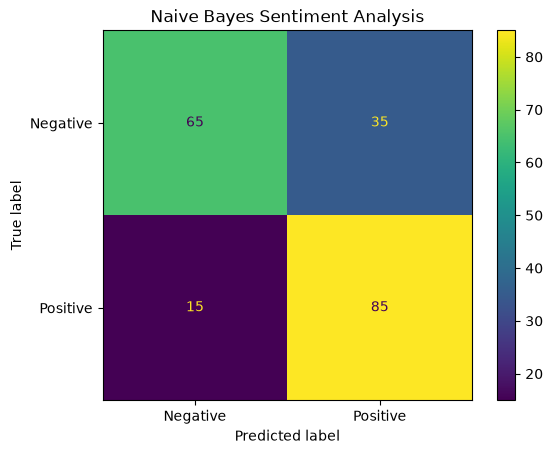

In [44]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Test reviews ki predictions
y_pred = model.predict(X_test_text)

# Accuracy calculate karna
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy percentage: {accuracy * 100:.2f}%")

# Precision, recall aur F1-score
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"],
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print("\nConfusion Matrix:")
print(cm)

# Confusion matrix ka chart
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)
display.plot()
plt.title("Naive Bayes Sentiment Analysis")
plt.show()


In [45]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# TF-IDF aur SVM ki pipeline
svm_model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LinearSVC(random_state=42))
])

# Training data par model train karna
svm_model.fit(X_train_text, y_train)

# Test data par predictions
svm_pred = svm_model.predict(X_test_text)

# Accuracy
svm_accuracy = accuracy_score(y_test, svm_pred)
print(f"SVM Accuracy: {svm_accuracy:.4f}")
print(f"SVM Accuracy Percentage: {svm_accuracy * 100:.2f}%")

# Detailed evaluation
print("\nSVM Classification Report:")
print(
    classification_report(
        y_test,
        svm_pred,
        target_names=["Negative", "Positive"],
        zero_division=0
    )
)

# Confusion matrix
print("\nSVM Confusion Matrix:")
print(confusion_matrix(y_test, svm_pred, labels=[0, 1]))


SVM Accuracy: 0.7650
SVM Accuracy Percentage: 76.50%

SVM Classification Report:
              precision    recall  f1-score   support

    Negative       0.77      0.76      0.76       100
    Positive       0.76      0.77      0.77       100

    accuracy                           0.77       200
   macro avg       0.77      0.77      0.76       200
weighted avg       0.77      0.77      0.76       200


SVM Confusion Matrix:
[[76 24]
 [23 77]]


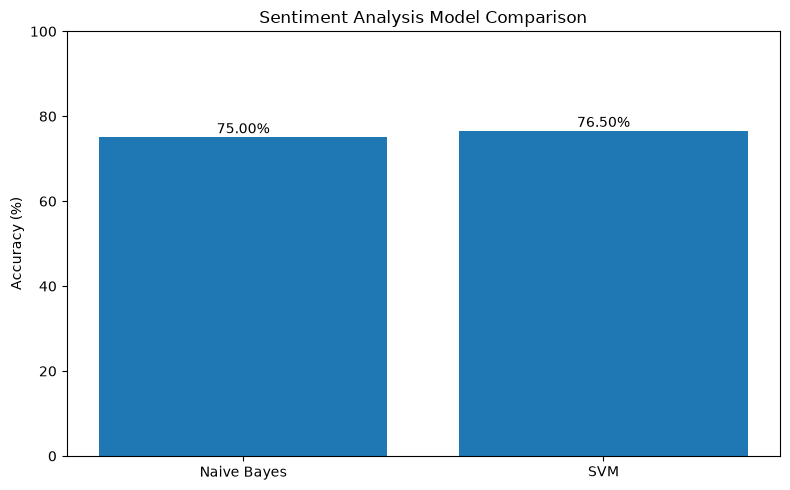

Chart saved in visualizations/model_comparison.png


In [46]:
import os
import matplotlib.pyplot as plt

# Create visualizations folder if it doesn't exist
os.makedirs("visualizations", exist_ok=True)

models = ["Naive Bayes", "SVM"]
accuracies = [accuracy * 100, svm_accuracy * 100]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies)

plt.title("Sentiment Analysis Model Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar, score in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{score:.2f}%",
        ha="center"
    )

plt.tight_layout()

# Save chart for GitHub
plt.savefig(
    "visualizations/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved in visualizations/model_comparison.png")

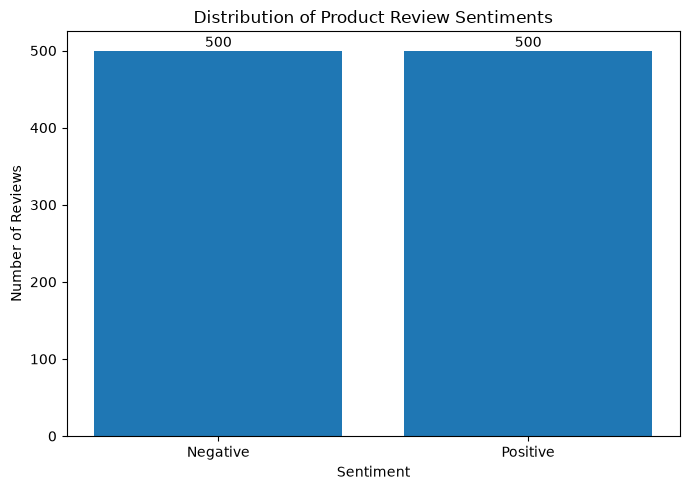

Sentiment distribution chart saved successfully!


In [47]:

import os
import matplotlib.pyplot as plt

os.makedirs("visualizations", exist_ok=True)

sentiment_counts = df["sentiment"].value_counts().sort_index()

labels = ["Negative", "Positive"]
values = [
    sentiment_counts.get(0, 0),
    sentiment_counts.get(1, 0)
]

plt.figure(figsize=(7, 5))
bars = plt.bar(labels, values)

plt.title("Distribution of Product Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        str(int(bar.get_height())),
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "visualizations/sentiment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Sentiment distribution chart saved successfully!")


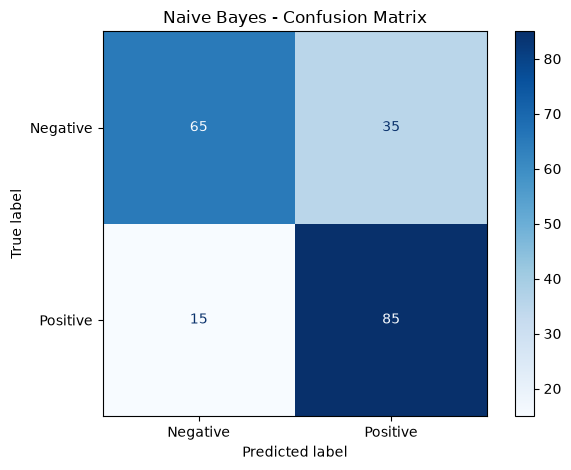

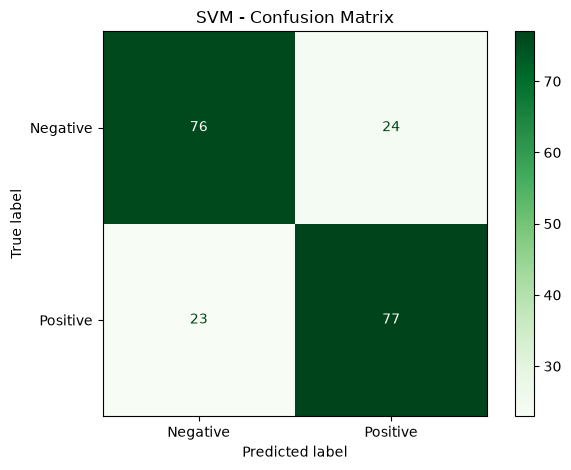

Both confusion matrix charts saved successfully!


In [48]:

import os
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

os.makedirs("visualizations", exist_ok=True)

# Naive Bayes confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Negative", "Positive"],
    cmap="Blues"
)

plt.title("Naive Bayes - Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "visualizations/naive_bayes_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# SVM confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    svm_pred,
    labels=[0, 1],
    display_labels=["Negative", "Positive"],
    cmap="Greens"
)

plt.title("SVM - Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "visualizations/svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Both confusion matrix charts saved successfully!")
